In [20]:
## importing the dataset

import pandas as pd
df = pd.read_csv("Advertising.csv")
df.head()

,Unnamed: 0,TV,radio,newspaper,sales
0,1,230.1,37.8,69.2,22.1
1,2,44.5,39.3,45.1,10.4
2,3,17.2,45.9,69.3,9.3
3,4,151.5,41.3,58.5,18.5
4,5,180.8,10.8,58.4,12.9


In [21]:
df.shape

(200, 5)

In [22]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  200 non-null    int64  
 1   TV          200 non-null    float64
 2   radio       200 non-null    float64
 3   newspaper   200 non-null    float64
 4   sales       200 non-null    float64
dtypes: float64(4), int64(1)
memory usage: 7.9 KB


In [23]:
print(df["Unnamed: 0"].head()) 

print("Unique values: ", df["Unnamed: 0" ].nunique())   ## Checking the unique values.
print("Missing values: ", df.isna().sum())   ## checking the missing values.
print("Duplicates rows: ",df.duplicated().sum())     ##Checking the duplicates.

0    1
1    2
2    3
3    4
4    5
Name: Unnamed: 0, dtype: int64
Unique values:  200
Missing values:  Unnamed: 0    0
TV            0
radio         0
newspaper     0
sales         0
dtype: int64
Duplicates rows:  0


In [24]:
# Remove the unnecessary index column.
df = df.drop(columns=["Unnamed: 0"])

## verify the change
print("Dataset shape: ", df.shape)
print("Columns: ",df.columns.tolist())


Dataset shape:  (200, 4)
Columns:  ['TV', 'radio', 'newspaper', 'sales']


In [25]:
print("Duplicate Rows: ",df.duplicated().sum())   # Checking the duplicated rows.

Duplicate Rows:  0


In [27]:
df.describe()

,TV,radio,newspaper,sales
count,200.000000,200.000000,200.000000,200.000000
mean,147.042500,23.264000,30.554000,14.022500
std,85.854236,14.846809,21.778621,5.217457
min,0.700000,0.000000,0.300000,1.600000
25%,74.375000,9.975000,12.750000,10.375000
50%,149.750000,22.900000,25.750000,12.900000
75%,218.825000,36.525000,45.100000,17.400000
max,296.400000,49.600000,114.000000,27.000000


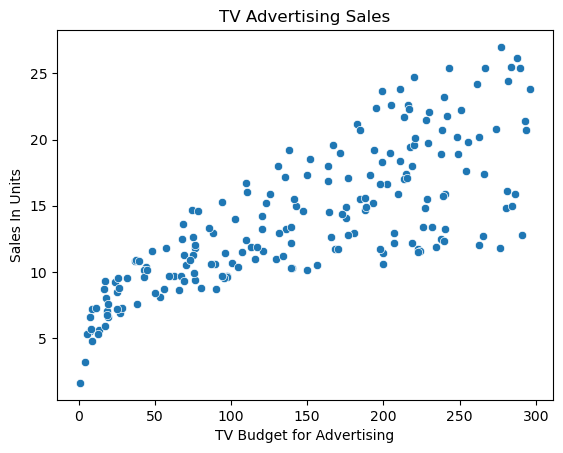

In [32]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.scatterplot(
    data = df,
    x = "TV",
    y = "sales"
)
plt.title("TV Advertising Sales")
plt.xlabel("TV Budget for Advertising")
plt.ylabel("Sales In Units")

plt.show()

In [35]:
df[["TV","sales"]].corr()

,TV,sales
TV,1.000000,0.782224
sales,0.782224,1.000000


In [38]:
## prepare the data for Linear Regression  we'll use TV advertising spending to predict sales.

# Input feature
X = df[["TV"]]

y = df["sales"]

# Target we want to predict
print("Feature Shape: ",X.shape)
print("Target Values ",y.shape)
     



Feature Shape:  (200, 1)
Target Values  (200,)


In [39]:
from sklearn.model_selection import train_test_split

X_train,X_test,y_train,y_test = train_test_split(
    X,
    y,
    test_size = 0.2,
    random_state = 42
)
print("X_train: ",X_train.shape)
print("X_test: ",X_test.shape)
print("y_train: ",y_train.shape)
print("y_test: ",y_test.shape)

X_train:  (160, 1)
X_test:  (40, 1)
y_train:  (160,)
y_test:  (40,)


In [41]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train,y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [42]:
print("Sloap: ",model.coef_[0])
print("Intercept: ",model.intercept_)

Sloap:  0.04652973370544335
Intercept:  7.1196384305929525


In [43]:
# Predict sales for the test data
y_pred = model.predict(X_test)

print(y_pred[:10])

[14.71794394 16.2115484  20.74819743  7.66403631 17.37013877 10.61402143
 17.2072847   9.44612512 17.46785121 15.2669948 ]


In [64]:
comparison = pd.DataFrame({
    "TV_Advertising" : X_test["TV"].values,
    "Actual_Sales" : y_test.values,
    "Predicted_Sales" : y_pred
})
comparison.head(10)  

,TV_Advertising,Actual_Sales,Predicted_Sales
0,163.3,16.9,14.717944
1,195.4,22.4,16.211548
2,292.9,21.4,20.748197
3,11.7,7.3,7.664036
4,220.3,24.7,17.370139
5,75.1,12.6,10.614021
6,216.8,22.3,17.207285
7,50.0,8.4,9.446125
8,222.4,11.5,17.467851
9,175.1,14.9,15.266995


## Compares the actual values and preditred values errors
Calculate the prediction error
\[\text{Error}=\text{Actual sales}-\text{Predicted sales}\]

In [71]:
comparison["Error"] = (
    comparison["Actual_Sales"] - comparison["Predicted_Sales"]
)
comparison.head(10)

,TV_Advertising,Actual_Sales,Predicted_Sales,Error
0,163.3,16.9,14.717944,2.182056
1,195.4,22.4,16.211548,6.188452
2,292.9,21.4,20.748197,0.651803
3,11.7,7.3,7.664036,-0.364036
4,220.3,24.7,17.370139,7.329861
5,75.1,12.6,10.614021,1.985979
6,216.8,22.3,17.207285,5.092715
7,50.0,8.4,9.446125,-1.046125
8,222.4,11.5,17.467851,-5.967851
9,175.1,14.9,15.266995,-0.366995


What is MAE?
MAE stands for Mean Absolute Error.

Calculate MAE for your model

In [72]:
from sklearn.metrics import mean_absolute_error
mae = mean_absolute_error(y_test, y_pred)

print("MAE: ",mae)

MAE:  2.444420003751042


In [73]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error

# Create a simple baseline model
baseline = DummyRegressor(strategy="mean")

# Train it using the same training data
baseline.fit(X_train,y_train)

# Predict the test data
baseline_pred = baseline.predict(X_test)

# Evaluate its predictions
baseline_mae = mean_absolute_error(y_test, baseline_pred)

print("Baseline MAE: ", baseline_mae)
print("LinearRegression: ",mae)

## "I split the data into training and testing sets, trained Linear Regression using the training data, and generated predictions on the held-out test set.
##I evaluated the predictions using Mean Absolute Error and compared the result against a mean-based DummyRegressor baseline.
##Linear Regression achieved an MAE of approximately 2.44 thousand sales units, compared with 4.96 thousand for the baseline on the same test split.
##This indicates that Linear Regression performed better than the baseline on that split. I would use further validation before making a strong 
##claim about its generalization performance."

Baseline MAE:  4.9625
LinearRegression:  2.444420003751042


Visualize actual vs predicted sales

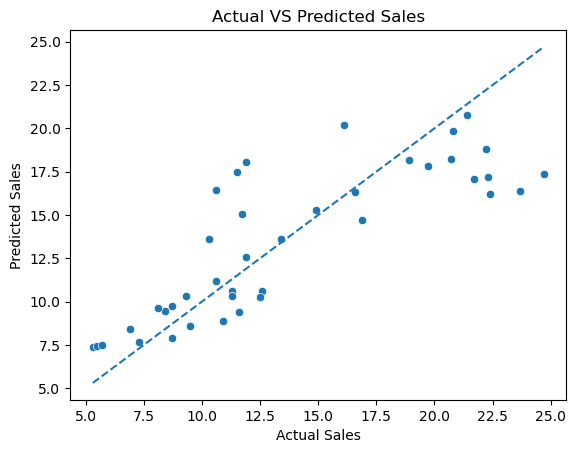

In [74]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.scatterplot(
    data = comparison,
    x = "Actual_Sales",
    y = "Predicted_Sales"
)
# Reference line: perfect predictions
low = min(
    comparison["Actual_Sales"].min(),
    comparison["Predicted_Sales"].min()
)
high = max(
    comparison["Actual_Sales"].max(),
    comparison["Predicted_Sales"].max()
    
)
plt.plot([low,high],[low,high],linestyle="--")

plt.title("Actual VS Predicted Sales")
plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")

plt.show()

In [76]:
mae_tv = mean_absolute_error(y_test,y_pred)

# Use all three advertising features
X = df[["TV","radio","newspaper"]]
y = df[["sales"]]

# Split the data using the same settings
X_train,X_test,y_train,y_test = train_test_split(
    X,
    y,
    test_size= 0.2,
    random_state=42
)
model_all = LinearRegression()
model_all.fit(X_train,y_train)

# Make predictions on the test data
y_pred_all = model_all.predict(X_test)

# Evaluate the predictions
mae_all = mean_absolute_error(y_test, y_pred_all)

print("MAE using TV only:", mae_tv)
print("MAE using all features:", mae_all)

MAE using TV only: 2.444420003751042
MAE using all features: 1.4607567168117606
